main_func

In [72]:
import numpy as np
import matplotlib.pyplot as plt

In [73]:
def getTargetFunction(functionName="sin_cos"):
    def sinCosFunction(t):
        return np.sin(2 * np.pi * t) + 5.0 * np.cos(4 * np.pi * t)
    def linearFunction(t):
        return 2 * t + 1
    def quadraticFunction(t):
        return 4 * (t**2) - 4 * t + 2
    def cubicFunction(t):
        return 8 * (t**3) - 12 * (t**2) + 6 * t
    def gaussianFunction(t):
        mu = 5.0
        sigma = 1.0
        return np.exp(-((t - mu) ** 2) / (2 * sigma**2))
    def squareWaveFunction(t):
        return 5.0 * (np.sign(np.sin(2 * np.pi * t)) + 1)
    def sawtoothFunction(t):
        return (t * 5) % 1
    def complexFourierFunction(t):
        return (
        np.sin(2 * np.pi * t)
        + 3.0 * np.cos(4 * np.pi * t)
        + 2.0 * np.sin(6 * np.pi * t)
        + 1.0 * np.cos(8 * np.pi * t)
)
    def polynomialFunction(t):
        return 10 * (t**5) - 20 * (t**4) + 15 * (t**3) - 4 * (t**2) + t + 5.0
    functionOptions = {
        "sin_cos": sinCosFunction,
    
"linear": linearFunction,
"quadratic": quadraticFunction,
"cubic": cubicFunction,
"gaussian": gaussianFunction,
"square_wave": squareWaveFunction,
"sawtooth": sawtoothFunction,
"complex_fourier": complexFourierFunction,
"polynomial": polynomialFunction,
}
    selectedFunction = functionOptions.get(functionName.lower())
    if selectedFunction:
        return selectedFunction
def cost_func(state, tSamples, fSamples):
    a=[]
    b=[0]
    
    for i in range(21):
        a.append(state[i])
    for i in range(21,41):
        b.append(state[i])

        
    

    
    f_estimate = []

    for x in tSamples:
        ans = a[0] / 2
        for i in range(1, len(a)):
            ans += a[i] * np.cos(i * x) + b[i] * np.sin(i * x)
        f_estimate.append(ans)

    f_estimate = np.array(f_estimate)
    rmse = np.sqrt(np.mean((fSamples - f_estimate) ** 2))
    return rmse
def next_state(state, num_changes=3, delta=0.5, A=10):
    new_state = np.copy(state)
    
    indices = np.random.choice(len(state), num_changes, replace=False)
    
    for idx in indices:
        new_state[idx] += np.random.uniform(-delta, delta)
    
    return np.clip(new_state, -A, A)
def simulated_annealing(fSamples, tSamples, initial_state, T_0=1000, alpha=0.95, max_iter=3000, sigma=0.2):
    current_state = initial_state.copy()
    current_cost = cost_func(current_state, tSamples, fSamples)
    
    best_state = current_state.copy()
    best_cost = current_cost

    T = T_0
    errors = []

    for epoch in range(max_iter):
        new_state = next_state(current_state, delta=sigma)
        new_cost = cost_func(new_state, tSamples, fSamples)

        if new_cost < current_cost or np.random.rand() < np.exp((current_cost - new_cost) / T):
            current_state = new_state
            current_cost = new_cost

        if new_cost < best_cost:
            best_cost = new_cost
            best_state = new_state

        T *= alpha
        errors.append(current_cost)

        if epoch % 100 == 0:
            print(f"Iteration {epoch}/{max_iter}, Cost: {current_cost:.6f}, Best: {best_cost:.6f}, T: {T:.4f}")

    return best_state, errors




In [74]:
def Simulated_annealing(func_name, A_star, sample_size, T, sigma, alpha, max_iter):
    N = 20
    functionRange = (-np.pi, np.pi)
    tSamples = np.linspace(functionRange[0], functionRange[1], sample_size)
    fSamples = getTargetFunction(func_name)(tSamples)

    A = A_star
    a0 = np.random.uniform(-A, A)
    a = np.random.uniform(-A, A, N)
    b = np.random.uniform(-A, A, N)
    init_state = np.concatenate(([a0], a, b))

    optimal_state, errors = simulated_annealing(fSamples, tSamples, init_state, T, alpha, max_iter, sigma)

    def state_func(x, optimal_state):
        a = optimal_state[:21]
        b = optimal_state[21:]
        ans = a[0] / 2
        for n in range(1, len(b) + 1):
            ans += a[n] * np.cos(n * x) + b[n - 1] * np.sin(n * x)
        return ans

    fst = state_func(tSamples, optimal_state)
    plt.figure(figsize=(10, 5))
    plt.plot(tSamples, fSamples, label='Target Function', linewidth=2)
    plt.plot(tSamples, fst, label='Fourier Approximation', linestyle='--', linewidth=2)
    plt.legend()
    plt.show()

    return optimal_state, errors


Iteration 0/3000, Cost: 26.758245, Best: 26.718125, T: 9500.0000
Iteration 100/3000, Cost: 27.067067, Best: 26.529539, T: 56.2450
Iteration 200/3000, Cost: 26.668408, Best: 26.389024, T: 0.3330
Iteration 300/3000, Cost: 24.891889, Best: 24.891889, T: 0.0020
Iteration 400/3000, Cost: 23.012917, Best: 23.012917, T: 0.0000
Iteration 500/3000, Cost: 20.715618, Best: 20.715618, T: 0.0000
Iteration 600/3000, Cost: 18.418768, Best: 18.418768, T: 0.0000
Iteration 700/3000, Cost: 16.656510, Best: 16.656510, T: 0.0000
Iteration 800/3000, Cost: 14.620945, Best: 14.620945, T: 0.0000
Iteration 900/3000, Cost: 12.541292, Best: 12.541292, T: 0.0000
Iteration 1000/3000, Cost: 10.529563, Best: 10.529563, T: 0.0000
Iteration 1100/3000, Cost: 8.584862, Best: 8.584862, T: 0.0000
Iteration 1200/3000, Cost: 7.156250, Best: 7.156250, T: 0.0000
Iteration 1300/3000, Cost: 5.671566, Best: 5.671566, T: 0.0000
Iteration 1400/3000, Cost: 4.643005, Best: 4.643005, T: 0.0000
Iteration 1500/3000, Cost: 3.637950, Best

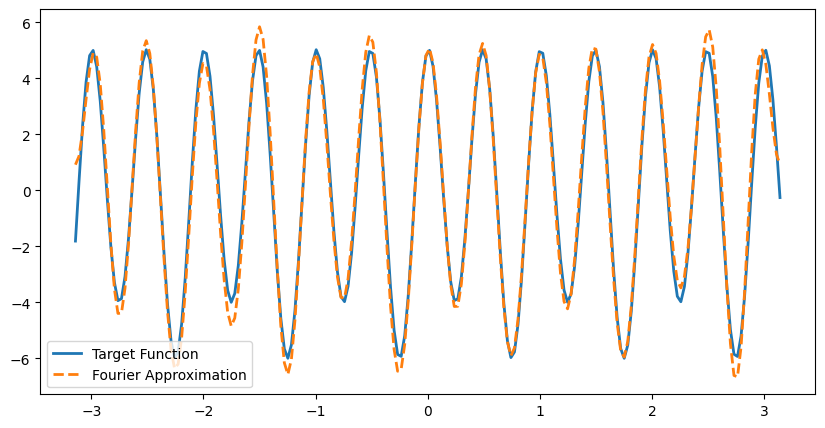

In [75]:
ans=Simulated_annealing("sin_cos",10,200,10000,0.5,0.95,3000)

Linear

Iteration 0/3000, Cost: 24.050001, Best: 24.024717, T: 99.0000
Iteration 100/3000, Cost: 24.465713, Best: 24.024717, T: 36.2372
Iteration 200/3000, Cost: 24.846511, Best: 24.024717, T: 13.2640
Iteration 300/3000, Cost: 25.855054, Best: 24.024717, T: 4.8550
Iteration 400/3000, Cost: 25.223956, Best: 24.024717, T: 1.7771
Iteration 500/3000, Cost: 25.268164, Best: 24.024717, T: 0.6505
Iteration 600/3000, Cost: 25.133479, Best: 24.024717, T: 0.2381
Iteration 700/3000, Cost: 24.135306, Best: 24.024717, T: 0.0872
Iteration 800/3000, Cost: 23.560482, Best: 23.560482, T: 0.0319
Iteration 900/3000, Cost: 22.365780, Best: 22.365780, T: 0.0117
Iteration 1000/3000, Cost: 20.510820, Best: 20.510820, T: 0.0043
Iteration 1100/3000, Cost: 18.592552, Best: 18.592552, T: 0.0016
Iteration 1200/3000, Cost: 16.531388, Best: 16.531388, T: 0.0006
Iteration 1300/3000, Cost: 14.845499, Best: 14.845499, T: 0.0002
Iteration 1400/3000, Cost: 13.331404, Best: 13.331404, T: 0.0001
Iteration 1500/3000, Cost: 11.6850

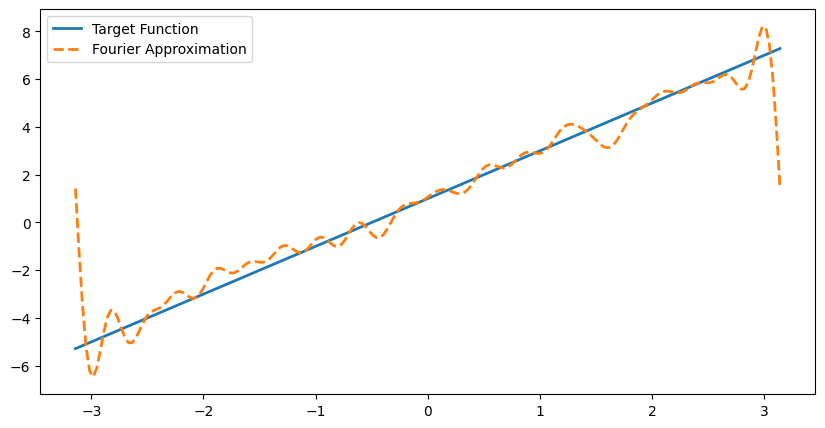

In [76]:
ans=Simulated_annealing("linear",10,200,100,0.5,0.99,3000)

quadratic

Iteration 0/5000, Cost: 32.807653, Best: 32.788481, T: 9900.0000
Iteration 100/5000, Cost: 32.164094, Best: 32.164094, T: 3623.7202
Iteration 200/5000, Cost: 32.222254, Best: 31.880946, T: 1326.3988
Iteration 300/5000, Cost: 32.500433, Best: 31.880946, T: 485.5049
Iteration 400/5000, Cost: 33.463763, Best: 31.880946, T: 177.7105
Iteration 500/5000, Cost: 32.691780, Best: 31.880946, T: 65.0478
Iteration 600/5000, Cost: 33.102511, Best: 31.880946, T: 23.8096
Iteration 700/5000, Cost: 32.895255, Best: 31.880946, T: 8.7151
Iteration 800/5000, Cost: 32.668029, Best: 31.880946, T: 3.1900
Iteration 900/5000, Cost: 32.420753, Best: 31.880946, T: 1.1676
Iteration 1000/5000, Cost: 32.482981, Best: 31.880946, T: 0.4274
Iteration 1100/5000, Cost: 32.224204, Best: 31.880946, T: 0.1564
Iteration 1200/5000, Cost: 31.948959, Best: 31.819481, T: 0.0573
Iteration 1300/5000, Cost: 30.766449, Best: 30.766449, T: 0.0210
Iteration 1400/5000, Cost: 29.536705, Best: 29.536705, T: 0.0077
Iteration 1500/5000, C

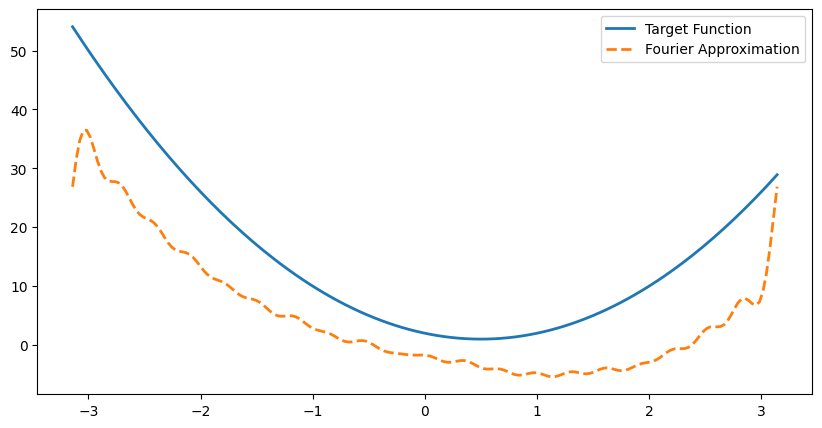

In [77]:
ans=Simulated_annealing("quadratic",10,200,10000,0.4,0.99,5000)

cubic

Iteration 0/3500, Cost: 26.966755, Best: 26.952594, T: 7680.0000
Iteration 100/3500, Cost: 26.802367, Best: 26.670260, T: 129.5641
Iteration 200/3500, Cost: 26.802942, Best: 26.670260, T: 2.1858
Iteration 300/3500, Cost: 26.869951, Best: 26.626738, T: 0.0369
Iteration 400/3500, Cost: 26.052482, Best: 26.052482, T: 0.0006
Iteration 500/3500, Cost: 25.205007, Best: 25.205007, T: 0.0000
Iteration 600/3500, Cost: 24.138414, Best: 24.138414, T: 0.0000
Iteration 700/3500, Cost: 22.957666, Best: 22.957666, T: 0.0000
Iteration 800/3500, Cost: 21.829872, Best: 21.829872, T: 0.0000
Iteration 900/3500, Cost: 20.546676, Best: 20.546676, T: 0.0000
Iteration 1000/3500, Cost: 19.323856, Best: 19.323856, T: 0.0000
Iteration 1100/3500, Cost: 18.485115, Best: 18.485115, T: 0.0000
Iteration 1200/3500, Cost: 17.398206, Best: 17.398206, T: 0.0000
Iteration 1300/3500, Cost: 16.468441, Best: 16.468441, T: 0.0000
Iteration 1400/3500, Cost: 15.615006, Best: 15.615006, T: 0.0000
Iteration 1500/3500, Cost: 14.59

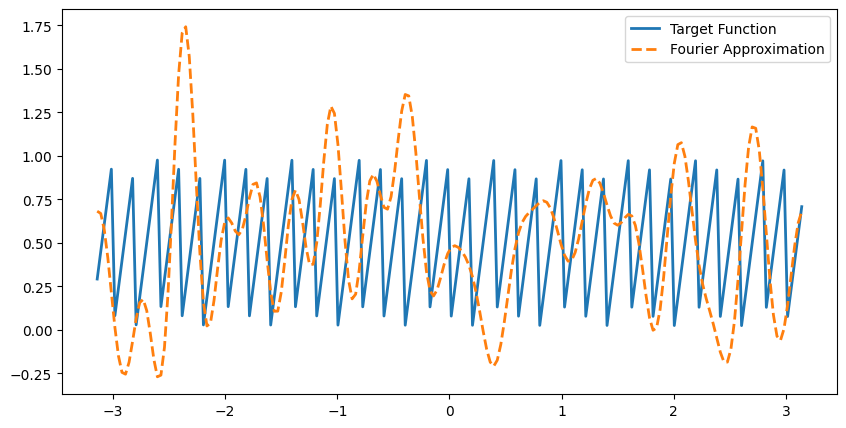

In [80]:
ans=Simulated_annealing("sawtooth",10,200,8000,0.25,0.96,3500)

Q1
Q1
Question 1
Definition of the state space:
The state space is essentially a 41-dimensional vector consisting of the coefficients a and b, where each value ranges between -10 and +10. Therefore, the state space includes all such vectors under these conditions, meaning that the state space is continuous

Q2

Question 2
Define the parameters and hyperparameters of the problem. Explain the difference between them.

Hyperparameters are variables that must be defined before running the algorithm. They control the behavior and performance of the optimization process — for example, the learning rate in gradient descent. Choosing different values for hyperparameters does not directly change the solution itself but affects how quickly or accurately the algorithm converges.

Parameters, on the other hand, are the actual values that the algorithm tries to find as the solution to the problem. They are adjusted during the optimization process.

In this example:

Hyperparameters: Temperature (T), α (cooling rate), and σ (step size).

Parameters: The coefficients a and b.

Q4
In the Simulated Annealing algorithm, the concept of temperature (T) controls the probability of accepting worse solutions.

At high temperatures, the algorithm explores the search space more freely, helping it escape local minima.

As temperature decreases, the algorithm becomes more selective, focusing on fine-tuning near the best solutions.
If the cooling rate (α) is too high (temperature drops too fast), the algorithm may get stuck in local minima and fail to find the global optimum.
If α is too low, the temperature decreases very slowly, leading to unnecessary long computation time.
Thus, a balanced cooling rate (e.g., 0.95–0.97) provides a good trade-off between exploration and convergence.

standard temp

Iteration 0/3500, Cost: 27.149663, Best: 27.149663, T: 7680.0000
Iteration 100/3500, Cost: 26.834146, Best: 26.833297, T: 129.5641
Iteration 200/3500, Cost: 27.068834, Best: 26.732957, T: 2.1858
Iteration 300/3500, Cost: 26.551232, Best: 26.474543, T: 0.0369
Iteration 400/3500, Cost: 25.569107, Best: 25.569107, T: 0.0006
Iteration 500/3500, Cost: 24.167341, Best: 24.167341, T: 0.0000
Iteration 600/3500, Cost: 23.259237, Best: 23.259237, T: 0.0000
Iteration 700/3500, Cost: 22.261263, Best: 22.261263, T: 0.0000
Iteration 800/3500, Cost: 20.922022, Best: 20.922022, T: 0.0000
Iteration 900/3500, Cost: 20.103331, Best: 20.103331, T: 0.0000
Iteration 1000/3500, Cost: 18.975816, Best: 18.975816, T: 0.0000
Iteration 1100/3500, Cost: 17.955086, Best: 17.955086, T: 0.0000
Iteration 1200/3500, Cost: 16.841346, Best: 16.841346, T: 0.0000
Iteration 1300/3500, Cost: 15.953864, Best: 15.953864, T: 0.0000
Iteration 1400/3500, Cost: 14.879784, Best: 14.879784, T: 0.0000
Iteration 1500/3500, Cost: 13.82

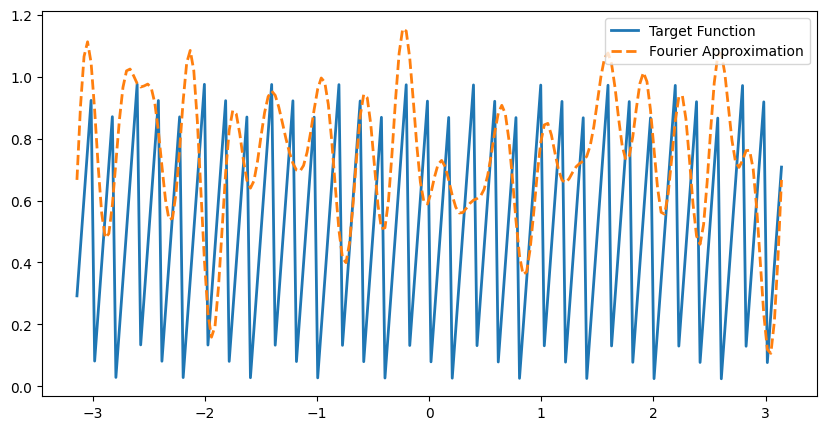

In [86]:
ans=Simulated_annealing("sawtooth",10,200,8000,0.25,0.96,3500)

high temp

Iteration 0/3000, Cost: 26.290183, Best: 26.231979, T: 990000.0000
Iteration 100/3000, Cost: 26.697956, Best: 26.010130, T: 362372.0179
Iteration 200/3000, Cost: 26.150565, Best: 26.010130, T: 132639.8781
Iteration 300/3000, Cost: 26.135186, Best: 25.580522, T: 48550.4851
Iteration 400/3000, Cost: 26.238543, Best: 25.580522, T: 17771.0477
Iteration 500/3000, Cost: 26.270641, Best: 25.580522, T: 6504.7782
Iteration 600/3000, Cost: 26.342791, Best: 25.580522, T: 2380.9592
Iteration 700/3000, Cost: 26.469977, Best: 25.580522, T: 871.5081
Iteration 800/3000, Cost: 26.464246, Best: 25.580522, T: 319.0001
Iteration 900/3000, Cost: 25.933920, Best: 25.580522, T: 116.7644
Iteration 1000/3000, Cost: 25.525981, Best: 25.380352, T: 42.7395
Iteration 1100/3000, Cost: 25.857985, Best: 25.380352, T: 15.6441
Iteration 1200/3000, Cost: 26.099859, Best: 25.380352, T: 5.7262
Iteration 1300/3000, Cost: 27.283129, Best: 25.380352, T: 2.0960
Iteration 1400/3000, Cost: 26.971208, Best: 25.380352, T: 0.7672


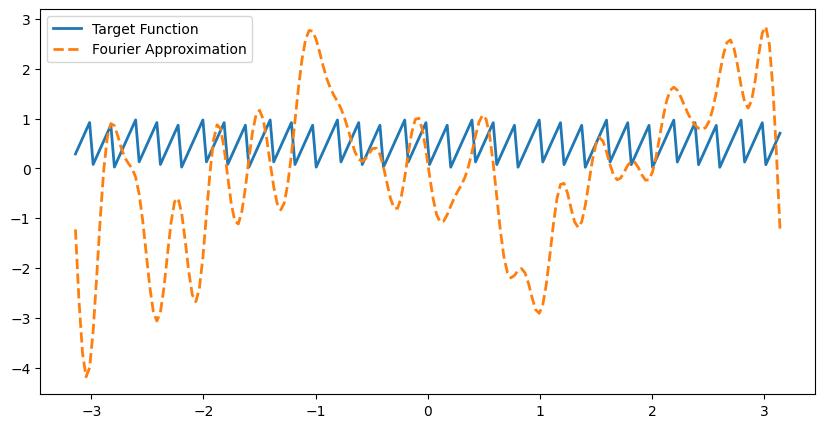

In [87]:
ans=Simulated_annealing("sawtooth",10,200,1000000,0.5,0.99,3000)

low temp

Iteration 0/2000, Cost: 28.251568, Best: 28.251568, T: 0.0003
Iteration 100/2000, Cost: 25.064547, Best: 25.064547, T: 0.0000
Iteration 200/2000, Cost: 22.161768, Best: 22.161768, T: 0.0000
Iteration 300/2000, Cost: 19.729406, Best: 19.729406, T: 0.0000
Iteration 400/2000, Cost: 16.531574, Best: 16.531574, T: 0.0000
Iteration 500/2000, Cost: 13.871919, Best: 13.871919, T: 0.0000
Iteration 600/2000, Cost: 11.259879, Best: 11.259879, T: 0.0000
Iteration 700/2000, Cost: 8.422530, Best: 8.422530, T: 0.0000
Iteration 800/2000, Cost: 6.357500, Best: 6.357500, T: 0.0000
Iteration 900/2000, Cost: 4.589327, Best: 4.589327, T: 0.0000
Iteration 1000/2000, Cost: 2.985443, Best: 2.985443, T: 0.0000
Iteration 1100/2000, Cost: 2.068058, Best: 2.068058, T: 0.0000
Iteration 1200/2000, Cost: 1.181840, Best: 1.181840, T: 0.0000
Iteration 1300/2000, Cost: 0.965598, Best: 0.965598, T: 0.0000
Iteration 1400/2000, Cost: 0.839238, Best: 0.839238, T: 0.0000
Iteration 1500/2000, Cost: 0.796423, Best: 0.796423, 

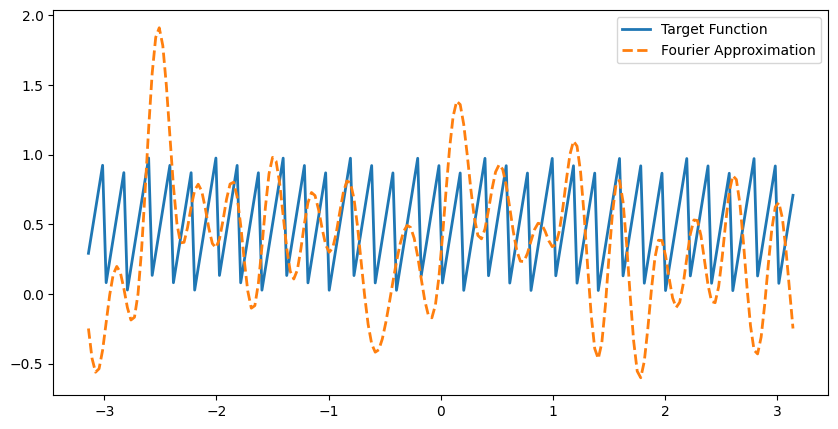

In [91]:
ans=Simulated_annealing("sawtooth",10,200,0.0003,0.7,0.98,2000)

Q5
Small Random Perturbation:
Slightly change a few coefficients in the state by adding small random noise (e.g., ±0.2).
→ Keeps search local and stable — good for fine-tuning near optimal solutions.

Multiple Random Changes:
Randomly select several coefficients and modify them by larger values.
→ Increases exploration — helps escape local minima but may slow convergence.

Swap-based Change:
Randomly swap two coefficients from the state vector.
→ Preserves overall energy but allows structural rearrangement — useful for diverse search patterns.

Comparison:
Small perturbations yield smooth convergence but risk local minima.
Larger/multiple changes improve exploration but may reduce stability.
Swap-based changes balance both in some cases.

Choice:
The small random perturbation method is preferred here because it fits continuous coefficient optimization and provides stable, smooth convergence toward the target Fourier coefficients.